<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/05b_benchmark_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 5b: Final Benchmark, Error Analysis and Ablation

**Goal:** Evaluate the GRU properly (several seeds), compare it with published results, understand where it fails, and test whether two engine-specific sensors (s9, s14) are worth keeping.

**Protocol**
- For every subset, both the default and the tuned configuration (Notebook 5a) are trained with 5 seeds; each seed also uses a different engine split for early stopping. Mean and standard deviation over seeds are reported, plus the result of averaging the 5 models (ensemble).
- The configuration used as the final one was fixed beforehand from the validation results of Notebook 5a (tuned for FD001, FD002, FD004; default for FD003), not from test results.
- Evaluation: one prediction per test engine at its last recorded cycle, against the true RUL file; the training target is capped at 125.

## 1. Setup
Load windows, tuned parameters and feature lists.

In [1]:
import os, json, copy, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'
os.makedirs(f'{PROC_DIR}/models', exist_ok=True)

SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
CAP = 125
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

W = {fd: dict(np.load(f'{PROC_DIR}/windows_{fd}.npz')) for fd in SUBSETS}
TUNED = json.load(open(f'{PROC_DIR}/best_params.json'))
FEATS = json.load(open(f'{PROC_DIR}/features.json'))

DEFAULT = {'win': 30, 'hidden': 64, 'layers': 2, 'dropout': 0.2,
           'lr': 1e-3, 'wd': 0.0, 'batch': 256}

# fixed in advance from the VALIDATION results of Notebook 5a
CHOSEN = {'FD001': 'tuned', 'FD002': 'tuned', 'FD003': 'default', 'FD004': 'tuned'}
print(TUNED['FD001'])

Mounted at /content/drive
device: cuda
{'win': 30, 'hidden': 64, 'layers': 2, 'dropout': 0.24348796170203224, 'lr': 0.00032496321067436586, 'wd': 1.5168530214362772e-06, 'batch': 256}


## 2. Model, metrics and training function
Same GRU and training procedure as in Notebook 5a (early stopping on held-out engines), now with up to 40 epochs and patience 8, and with a separate seed for the network and for the engine split.

In [2]:
def set_seed(s=42):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def nasa_contrib(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

def nasa_score(y_true, y_pred):
    return float(nasa_contrib(y_true, y_pred).sum())

class GRUNet(nn.Module):
    def __init__(self, n_feat, hidden, layers, dropout):
        super().__init__()
        self.rnn = nn.GRU(n_feat, hidden, layers, batch_first=True,
                          dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)

def predict(model, X):
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), 2048):
            outs.append(model(torch.tensor(X[i:i + 2048], dtype=torch.float32).to(device)).cpu())
    return torch.cat(outs).numpy()

def fit(params, X, y, units, seed=42, split_seed=42, epochs=40, patience=8):
    set_seed(seed)
    X = X[:, -params['win']:, :]
    tr_idx, va_idx = next(GroupShuffleSplit(1, test_size=0.2, random_state=split_seed).split(X, groups=units))
    dl = DataLoader(TensorDataset(torch.tensor(X[tr_idx], dtype=torch.float32),
                                  torch.tensor(y[tr_idx], dtype=torch.float32)),
                    batch_size=params['batch'], shuffle=True)
    model = GRUNet(X.shape[2], params['hidden'], params['layers'], params['dropout']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['wd'])
    loss_fn = nn.MSELoss()
    best, best_state, bad = float('inf'), None, 0
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        v = rmse(y[va_idx], predict(model, X[va_idx]))
        if v < best - 1e-3:
            best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best

## 3. Five seeds, two configurations, four subsets
For each combination, five networks are trained (seeds 0-4, each with its own engine split) and evaluated on the last window of every test engine. The predictions and weights are kept for the ensemble and for later analysis.

In [3]:
def run_config(fd, params, seeds=range(5)):
    d = W[fd]
    Xte = d['X_test'][:, -params['win']:, :]
    y = d['y_test_true']
    rows, preds, states = [], [], []
    for s in seeds:
        model, val = fit(params, d['X_train'], d['y_train'], d['units_train'], seed=s, split_seed=s)
        p = predict(model, Xte)
        rows.append({'seed': s, 'val_rmse': val, 'test_rmse': rmse(y, p),
                     'test_rmse_capped': rmse(np.minimum(y, CAP), p), 'nasa_score': nasa_score(y, p)})
        preds.append(p)
        states.append(copy.deepcopy(model.state_dict()))
    return pd.DataFrame(rows), np.stack(preds), states

runs, PRED, STATES = {}, {}, {}
for fd in SUBSETS:
    for cfg, params in [('default', DEFAULT), ('tuned', TUNED[fd])]:
        t0 = time.time()
        df, P, S = run_config(fd, params)
        runs[(fd, cfg)], PRED[(fd, cfg)], STATES[(fd, cfg)] = df, P, S
        print(f'{fd} {cfg:7s} | test RMSE {df.test_rmse.mean():.2f} +/- {df.test_rmse.std():.2f} | {time.time() - t0:.0f}s')

pd.concat({k: v for k, v in runs.items()}, names=['subset', 'config']).reset_index(level=2, drop=True).to_csv(f'{PROC_DIR}/seed_runs.csv')

FD001 default | test RMSE 15.54 +/- 0.51 | 41s
FD001 tuned   | test RMSE 15.64 +/- 0.27 | 63s
FD002 default | test RMSE 26.08 +/- 0.26 | 71s
FD002 tuned   | test RMSE 26.26 +/- 0.20 | 118s
FD003 default | test RMSE 14.72 +/- 0.76 | 63s
FD003 tuned   | test RMSE 14.27 +/- 0.44 | 63s
FD004 default | test RMSE 26.89 +/- 0.34 | 92s
FD004 tuned   | test RMSE 27.01 +/- 0.68 | 74s


## 4. Results: default vs. tuned
Mean and standard deviation over 5 seeds, and the result of averaging the five networks (ensemble). `chosen` marks the configuration fixed beforehand from the validation results.

In [4]:
rows = []
for (fd, cfg), df in runs.items():
    y = W[fd]['y_test_true']
    ens = PRED[(fd, cfg)].mean(axis=0)
    rows.append({'subset': fd, 'config': cfg, 'chosen': CHOSEN[fd] == cfg,
                 'rmse_mean': df.test_rmse.mean(), 'rmse_std': df.test_rmse.std(),
                 'rmse_capped_mean': df.test_rmse_capped.mean(),
                 'nasa_mean': df.nasa_score.mean(), 'nasa_std': df.nasa_score.std(),
                 'ens_rmse': rmse(y, ens), 'ens_nasa': nasa_score(y, ens)})
res = pd.DataFrame(rows)
res.round(2).to_csv(f'{PROC_DIR}/final_results.csv', index=False)
res.round(2)

,subset,config,chosen,rmse_mean,rmse_std,rmse_capped_mean,nasa_mean,nasa_std,ens_rmse,ens_nasa
0,FD001,default,False,15.54,0.51,14.44,535.30,129.52,15.16,492.94
1,FD001,tuned,True,15.64,0.27,14.68,590.00,89.01,15.32,551.85
2,FD002,default,False,26.08,0.26,13.99,6917.65,1346.05,25.86,6478.69
3,FD002,tuned,True,26.26,0.20,14.26,6586.80,296.25,26.04,6354.15
4,FD003,default,True,14.72,0.76,13.45,512.98,197.90,13.67,330.26
5,FD003,tuned,False,14.27,0.44,12.77,440.67,125.11,13.48,336.60
6,FD004,default,False,26.89,0.34,15.29,5445.22,904.28,26.60,4975.10
7,FD004,tuned,True,27.01,0.68,15.11,5811.89,1076.42,26.66,5292.71


## 5. Final results (chosen configuration)

In [5]:
fin = res[res['chosen']].copy()
fin['RMSE (5 seeds)'] = fin.apply(lambda r: f'{r.rmse_mean:.2f} ± {r.rmse_std:.2f}', axis=1)
fin['NASA score (5 seeds)'] = fin.apply(lambda r: f'{r.nasa_mean:,.0f} ± {r.nasa_std:,.0f}', axis=1)
fin['RMSE vs capped truth'] = fin['rmse_capped_mean'].round(2)
fin['Ensemble RMSE'] = fin['ens_rmse'].round(2)
fin['Ensemble NASA'] = fin['ens_nasa'].round(0).astype(int)
fin[['subset', 'config', 'RMSE (5 seeds)', 'NASA score (5 seeds)', 'RMSE vs capped truth', 'Ensemble RMSE', 'Ensemble NASA']].set_index('subset')

,config,RMSE (5 seeds),NASA score (5 seeds),RMSE vs capped truth,Ensemble RMSE,Ensemble NASA
subset,,,,,,
FD001,tuned,15.64 ± 0.27,590 ± 89,14.68,15.32,552
FD002,tuned,26.26 ± 0.20,"6,587 ± 296",14.26,26.04,6354
FD003,default,14.72 ± 0.76,513 ± 198,13.45,13.67,330
FD004,tuned,27.01 ± 0.68,"5,812 ± 1,076",15.11,26.66,5293


## 6. Comparison with published results
RMSE values reported in the literature (copied from tables of other papers, to be verified against the original publications before citing). **Protocols differ between papers** (RUL cap, window length, evaluation on the last window or on all windows), so this is a rough positioning, not a strict ranking.

Our protocol: per-condition normalisation, windows of at most 30 cycles, training cap 125, one prediction per test engine at its last cycle against the true RUL file.

,FD001,FD002,FD003,FD004
"CNN (Babu et al., 2016)",18.44,30.29,19.81,29.15
"LSTM (Zheng et al., 2017)",16.14,24.49,16.18,28.17
CNN-LSTM (as listed in arXiv 2007.09868),14.40,27.23,14.32,26.69
Multi-head CNN+LSTM (2020; as listed in arXiv 2603.00745),12.19,19.93,12.85,22.89
DFormer (2024; as listed in arXiv 2603.00745),11.02,14.11,11.67,14.55
Ours: GRU (mean of 5 seeds),15.64,26.26,14.72,27.01
Ours: GRU (5-model ensemble),15.32,26.04,13.67,26.66


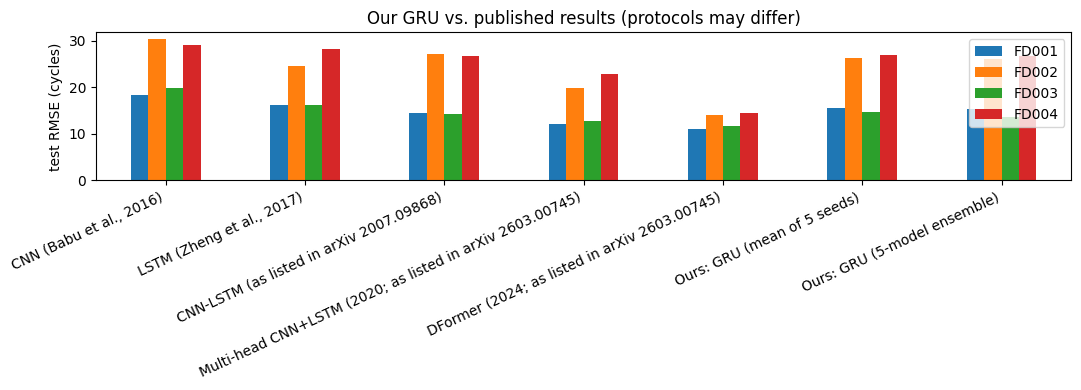

In [6]:
LIT = pd.DataFrame({
    'CNN (Babu et al., 2016)':                                  [18.44, 30.29, 19.81, 29.15],
    'LSTM (Zheng et al., 2017)':                                [16.14, 24.49, 16.18, 28.17],
    'CNN-LSTM (as listed in arXiv 2007.09868)':                 [14.40, 27.23, 14.32, 26.69],
    'Multi-head CNN+LSTM (2020; as listed in arXiv 2603.00745)': [12.19, 19.93, 12.85, 22.89],
    'DFormer (2024; as listed in arXiv 2603.00745)':            [11.02, 14.11, 11.67, 14.55],
}, index=SUBSETS).T

ours_mean = res[res['chosen']].set_index('subset').loc[SUBSETS]
comp = pd.concat([LIT,
                  pd.DataFrame({'Ours: GRU (mean of 5 seeds)': ours_mean['rmse_mean'].values,
                                'Ours: GRU (5-model ensemble)': ours_mean['ens_rmse'].values},
                               index=SUBSETS).T]).round(2)
display(comp)

comp.plot.bar(figsize=(11, 4))
plt.ylabel('test RMSE (cycles)'); plt.xticks(rotation=25, ha='right')
plt.title('Our GRU vs. published results (protocols may differ)')
plt.tight_layout(); plt.show()

## 7. Error analysis: where does the model fail?
Using the ensemble of the chosen configuration. Errors are grouped by the true remaining life; the mean signed error is predicted minus true (positive = over-estimate = late warning).
The last columns show how many engines are over-estimated and how much of the NASA score comes from these late predictions.

In [7]:
bins = [0, 30, 60, 100, 1000]
labels = ['0-30', '30-60', '60-100', '>100']
tables = {}
for fd in SUBSETS:
    y = W[fd]['y_test_true']
    p = PRED[(fd, CHOSEN[fd])].mean(axis=0)
    err = p - y
    g = pd.cut(y, bins=bins, labels=labels, include_lowest=True)
    t = pd.DataFrame({'true': y, 'err': err, 'group': g}).groupby('group', observed=True).agg(
        engines=('err', 'size'),
        rmse=('err', lambda e: np.sqrt(np.mean(e ** 2))),
        mean_signed_err=('err', 'mean')).round(1)
    tables[fd] = t
    c = nasa_contrib(y, p)
    print(f'{fd}: over-estimated engines {np.mean(err > 0) * 100:.0f}% | share of NASA score from late predictions {c[err >= 0].sum() / c.sum() * 100:.0f}%')
    display(t)

FD001: over-estimated engines 60% | share of NASA score from late predictions 84%


,engines,rmse,mean_signed_err
group,,,
0-30,25,2.5,0.7
30-60,14,11.1,4.9
60-100,28,22.8,13.4
>100,33,14.6,-5.3


FD002: over-estimated engines 43% | share of NASA score from late predictions 12%


,engines,rmse,mean_signed_err
group,,,
0-30,61,4.7,-0.2
30-60,41,12.8,4.5
60-100,65,19.9,8.5
>100,92,39.3,-28.2


FD003: over-estimated engines 53% | share of NASA score from late predictions 77%


,engines,rmse,mean_signed_err
group,,,
0-30,20,3.9,1.4
30-60,21,8.8,2.2
60-100,27,19.2,8.5
>100,32,14.5,-6.3


FD004: over-estimated engines 49% | share of NASA score from late predictions 17%


,engines,rmse,mean_signed_err
group,,,
0-30,53,6.4,4.1
30-60,38,16.4,5.0
60-100,57,20.6,8.4
>100,100,37.4,-28.7


## 8. Visual error analysis
Top row: predicted vs. true RUL per test engine (dashed line = perfect prediction, dotted line = training cap of 125). Bottom row: distribution of the errors.

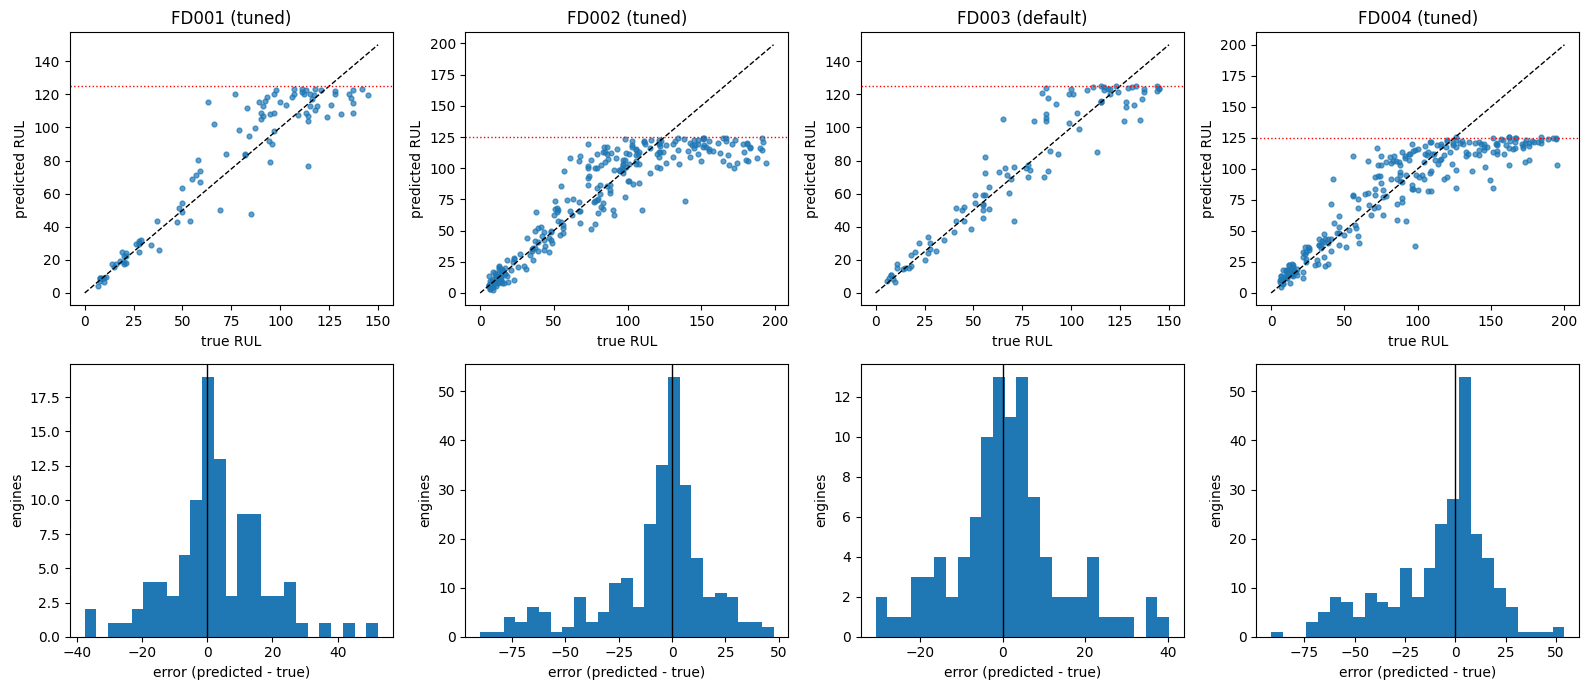

FD001


,unit,true_RUL,predicted,error
0,79,63,115.400002,52.4
1,67,77,120.400002,43.4
2,93,85,47.400002,-37.6
3,45,114,76.800003,-37.2
4,27,66,102.199997,36.2


FD002


,unit,true_RUL,predicted,error
0,86,194,104.099998,-89.9
1,166,188,108.099998,-79.9
2,256,191,114.400002,-76.6
3,170,182,105.800003,-76.2
4,235,190,115.900002,-74.1


FD003


,unit,true_RUL,predicted,error
0,34,65,105.300003,40.3
1,54,87,124.000000,37.0
2,19,85,120.699997,35.7
3,49,135,104.300003,-30.7
4,27,88,118.000000,30.0


FD004


,unit,true_RUL,predicted,error
0,127,195,103.400002,-91.6
1,19,194,124.199997,-69.8
2,246,194,125.000000,-69.0
3,54,176,107.099998,-68.9
4,122,192,124.500000,-67.5


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, fd in enumerate(SUBSETS):
    y = W[fd]['y_test_true']
    p = PRED[(fd, CHOSEN[fd])].mean(axis=0)
    ax = axes[0, j]
    ax.scatter(y, p, s=12, alpha=0.7)
    lim = max(y.max(), p.max()) + 5
    ax.plot([0, lim], [0, lim], 'k--', lw=1)
    ax.axhline(CAP, color='r', ls=':', lw=1)
    ax.set_title(f'{fd} ({CHOSEN[fd]})'); ax.set_xlabel('true RUL'); ax.set_ylabel('predicted RUL')
    axes[1, j].hist(p - y, bins=25)
    axes[1, j].axvline(0, color='k', lw=1)
    axes[1, j].set_xlabel('error (predicted - true)'); axes[1, j].set_ylabel('engines')
plt.tight_layout(); plt.show()

# the five worst engines per subset
for fd in SUBSETS:
    y = W[fd]['y_test_true']
    p = PRED[(fd, CHOSEN[fd])].mean(axis=0)
    w = pd.DataFrame({'unit': W[fd]['units_test'], 'true_RUL': y, 'predicted': p.round(1), 'error': (p - y).round(1)})
    print(fd); display(w.reindex(w['error'].abs().sort_values(ascending=False).index).head(5).reset_index(drop=True))

## 9. Ablation: are the engine-specific sensors s9 and s14 needed?
In the EDA, s9 and s14 behaved differently from engine to engine and correlated weakly with RUL. Here they are removed and the chosen configuration is retrained with the same 5 seeds, to test directly whether they help or hurt.

In [9]:
abl_rows = []
for fd in SUBSETS:
    params = TUNED[fd] if CHOSEN[fd] == 'tuned' else DEFAULT
    keep = [i for i, s in enumerate(FEATS[fd]) if s not in ('s9', 's14')]
    d = W[fd]
    Xtr, Xte = d['X_train'][:, :, keep], d['X_test'][:, -params['win']:, :][:, :, keep]
    r = []
    for s in range(5):
        model, _ = fit(params, Xtr, d['y_train'], d['units_train'], seed=s, split_seed=s)
        r.append(rmse(d['y_test_true'], predict(model, Xte)))
    full = runs[(fd, CHOSEN[fd])]['test_rmse']
    abl_rows.append({'subset': fd, 'features_full': len(FEATS[fd]), 'features_without_s9_s14': len(keep),
                     'rmse_full': f'{full.mean():.2f} ± {full.std():.2f}',
                     'rmse_without': f'{np.mean(r):.2f} ± {np.std(r, ddof=1):.2f}',
                     'diff': round(np.mean(r) - full.mean(), 2)})
    print(fd, 'done')

pd.DataFrame(abl_rows).set_index('subset')

FD001 done
FD002 done
FD003 done
FD004 done


,features_full,features_without_s9_s14,rmse_full,rmse_without,diff
subset,,,,,
FD001,14,12,15.64 ± 0.27,15.04 ± 0.26,-0.59
FD002,14,12,26.26 ± 0.20,26.26 ± 0.60,-0.00
FD003,15,13,14.72 ± 0.76,14.83 ± 0.47,0.10
FD004,15,13,27.01 ± 0.68,26.83 ± 0.18,-0.18


## 10. Saving models and predictions for the demo
For every subset, the five networks of the chosen configuration and their parameters are saved, together with the ensemble predictions for the test engines.

In [10]:
for fd in SUBSETS:
    cfg = CHOSEN[fd]
    params = TUNED[fd] if cfg == 'tuned' else DEFAULT
    torch.save({'params': params, 'config': cfg, 'n_feat': W[fd]['X_test'].shape[2],
                'states': STATES[(fd, cfg)]}, f'{PROC_DIR}/models/gru_{fd}.pt')
    p = PRED[(fd, cfg)].mean(axis=0)
    pd.DataFrame({'unit': W[fd]['units_test'], 'true_RUL': W[fd]['y_test_true'],
                  'predicted_RUL': p}).to_csv(f'{PROC_DIR}/predictions_{fd}.csv', index=False)
print(sorted(os.listdir(f'{PROC_DIR}/models')))

['gru_FD001.pt', 'gru_FD002.pt', 'gru_FD003.pt', 'gru_FD004.pt']


## 11. Key findings

- **Final results (GRU, 5 seeds, last-cycle evaluation):** test RMSE 15.64 ± 0.27 (FD001), 26.26 ± 0.20 (FD002), 14.72 ± 0.76 (FD003) and 27.01 ± 0.68 (FD004), and NASA scores of 590, 6,587, 513 and 5,812. Compared with the best untuned baseline of Notebook 3 this is a reduction in RMSE of about 22%, 7%, 31% and 9%, and the NASA score is lower on all four subsets. Averaging the five networks improves the RMSE slightly (15.32, 26.04, 13.67, 26.66).
- **Seeds matter:** the single-seed FD003 result of Notebook 4 (13.13) was favourable; the five-seed mean is 14.72 ± 0.76. Seed-to-seed standard deviations are 0.2-0.8 RMSE points, so differences smaller than that should not be interpreted.
- **Tuning did not help on the test set:** default and tuned configurations are within seed noise on all subsets (for example 15.54 ± 0.51 vs 15.64 ± 0.27 on FD001), consistent with the small validation gains in Notebook 5a. The configuration was fixed beforehand from validation results, and was not changed after seeing test results (on FD003 the tuned configuration was slightly better on the test set: 14.27 vs 14.72).
- **Position relative to the literature:** the GRU is comparable to classic LSTM and CNN-LSTM results (for example FD001 15.64 vs 14.40-16.14, FD003 14.72 vs 14.32-16.18) and better than the 2016 CNN, but clearly behind recent multi-head and Transformer-based models, especially on FD002 and FD004 (14-23 in the literature vs 26-27 here). Protocols differ between papers (window length, cap, evaluation convention), so this is a rough positioning, not a strict ranking.
- **Accuracy where it matters:** for engines with a true RUL below 30 cycles the RMSE is only 2.5 (FD001), 4.7 (FD002), 3.9 (FD003) and 6.4 (FD004).
- **Main weakness, late warnings at medium RUL:** for a true RUL of 60-100 cycles the RMSE is about 19-23 with a positive bias (over-estimates of +8 to +13 cycles). Late predictions generate 84% (FD001) and 77% (FD003) of the NASA score. The worst FD001 engines (units 79, 67, 27) are over-estimated by 36-52 cycles.
- **FD002/FD004 error is dominated by the RUL cap:** for engines with a true RUL above 100 the RMSE is 37-39 with a bias of about -28 cycles, because predictions saturate at about 105-125 while the true RUL reaches about 195. These are under-estimates (early warnings); late predictions contribute only 12% (FD002) and 17% (FD004) of the NASA score. Against the capped truth the RMSE is 14.3 and 15.1.
- **s9 and s14 are not needed:** removing them changes the RMSE by -0.59 (FD001), 0.00 (FD002), +0.10 (FD003) and -0.18 (FD004), mostly within noise, and clearly helps only on FD001.
- **Limitations:** a single architecture family was tuned (GRU); the search space was limited to windows of at most 30 cycles (longer windows were not tested); dropout is inactive for single-layer models; literature numbers were taken from secondary tables and must be verified against the original papers.
- **Next step:** Build the demo (Streamlit) with the saved models, write the README with the benchmark table and protocol notes, and add the resume bullets.